# Array 51904636 — is the shared block an operator, or a 16-step schedule?

**Stage S** showed that *one* block applied 16 times does direct deduction:
`tied_no_mlp T=16 d320`, 613,818 trainable, `rho_50` **0.757** with 3/3 seeds
crossing — 0.017 past the free line 0.740, so simpler than the untied twin and
worse than it, but not censored. That result makes a new question askable, and
only a *tied* cell can ask it.

A tied cell has a dial no untied cell has. `T`, the number of times the shared
block is applied, is a parameter **at eval time, on weights that are already
frozen**. An untied stack has no such dial: its depth *is* its weights, and
`--n-iters` refuses there rather than quietly scoring 16.

| reading | what it predicts for `T > 16` | what the analysable object is |
|---|---|---|
| **iterable operator** | quality holds; `T` is just the number of rounds | one map `F` with `h_{t+1} = F(h_t)` plus a stopping rule |
| **16-step schedule** | a peak at exactly 16, falling away both sides | one weight set tuned to a fixed trajectory; the recurrence is cosmetic |

**Nothing is trained in this stage.** The checkpoints are stage S's three d320
seeds, unchanged. `seed_start` is fixed, so every `T` sees the *same* 400
instances per bin and the differences below are **paired per-bin differences**.

The bars are reused, not refrozen around this run: free line **0.740** (stage
K), the easy-end bar **0.90** at realized `rho ≥ 0.85` (registered in this
stage), and `NEAR` **0.01** for "within" in T0 and T2. `rho_50` is the realized
hint density at which the solve rate crosses 0.5 on a 14-point grid of 400
instances per bin. **Lower is better.** Every eval is leak-free
(`--shuffle-adj`) and uses `--fall`, so the grid reaches `rho` 0.33.

## Provenance

Recorded so the numbers can be traced: array job, commit, config and seeds. The
config is the **stage S checkpoint's own** `config.json` — this stage trained
nothing, so there is no stage T training config to record.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
sys.path.insert(0, "/home/users/hshunt/.local/lib/claude-slides")

from scripts.staget_score import SCAN_T, TRAINED_T, T_GRID, EASY_RHO, EASY_BAR, NEAR
from scripts.stages_score import SCAN_S

CKPT = os.path.join(SCAN_S, "t00_d0320_ff01024_h04_tied_no_mlp_L16_s0",
                    "d0320_h04_L16_ff01024_lr1e-03_pre_shuf_fall_noff_tied")
cfg = json.load(open(os.path.join(CKPT, "config.json")))
print("eval array       51904636  (+51905401, the two reruns -- see below)")
print("scored by        51919538  (registered scorer, committed by 51904633)")
print("commit          ", subprocess.run(["git", "rev-parse", "--short", "HEAD"],
      cwd="/home/users/hshunt/spin_gnn", capture_output=True,
      text=True).stdout.strip())
print("grids dir        ", SCAN_T)
print("checkpoints      ", SCAN_S, "(stage S d320, UNCHANGED)")
print("seeds             0, 1, 2   |   T grid", T_GRID, " trained at T =", TRAINED_T)
print("bars              easy end >= %.2f at realized rho >= %.2f; NEAR %.2f"
      % (EASY_BAR, EASY_RHO, NEAR))
print()
print("the training config of the checkpoints being re-scored:")
for k in ("n_nodes", "degree", "n_colors", "arch_mode", "num_layers", "d_model",
          "nhead", "dim_feedforward", "n_train_instances", "epochs", "lr",
          "shuffle_adj", "fall", "warmup_frac", "n_trainable_params"):
    if k in cfg:
        print("  %-20s %s" % (k, cfg[k]))

eval array       51904636  (+51905401, the two reruns -- see below)
scored by        51919538  (registered scorer, committed by 51904633)
commit           aec838b
grids dir         /scratch/users/hshunt/spin_gnn/sudoku_n48_tiedT_T_2026-11-11
checkpoints       /scratch/users/hshunt/spin_gnn/sudoku_n48_tiedwidth_S_2026-11-10 (stage S d320, UNCHANGED)
seeds             0, 1, 2   |   T grid (4, 8, 12, 16, 20, 24)  trained at T = 16
bars              easy end >= 0.90 at realized rho >= 0.85; NEAR 0.01

the training config of the checkpoints being re-scored:
  n_nodes              48
  degree               5
  n_colors             4
  arch_mode            tied_no_mlp
  num_layers           16
  d_model              320
  nhead                4
  dim_feedforward      1024
  n_train_instances    240000
  epochs               50
  lr                   0.001
  shuffle_adj          True
  fall                 True
  n_trainable_params   613818


### Two eval cells failed and were rerun

`51904636_1` and `51904636_2` exited 1 after nine seconds; they were resubmitted
as `51905401` and completed. Eighteen grids are on disk, which is the full
6 × 3 design. The failures are recorded here rather than tidied away, and they
are inside the three-attempt limit.

In [2]:
print(subprocess.run(
    ["sacct", "-j", "51904636,51905401", "-X",
     "-o", "JobID%16,State,ExitCode,Elapsed"],
    capture_output=True, text=True).stdout)
print("grids on disk:", len([f for f in os.listdir(SCAN_T)
                             if f.startswith("rho_curve_")]))

           JobID      State ExitCode    Elapsed 
---------------- ---------- -------- ---------- 
      51904636_0  COMPLETED      0:0   01:06:22 
      51904636_1     FAILED      1:0   00:00:09 
      51904636_2     FAILED      1:0   00:00:08 
      51905401_1  COMPLETED      0:0   01:05:59 
      51905401_2  COMPLETED      0:0   01:01:40 

grids on disk: 18


## The registered scorer, run here

Read in the order it registers: **T1** (the easy end, which cannot censor) →
the level table → **T0** (operator or schedule) → **T2** (how many applications
are used) → **T3** (does depth pay where depth is needed). T1 outranks T0: a
representation that falls apart at `T=24` says nothing about deduction at
`T=24`.

In [3]:
r = subprocess.run([sys.executable, "-u", "-m", "scripts.staget_score"],
                   cwd="/home/users/hshunt/spin_gnn", capture_output=True, text=True)
print(r.stdout[-6000:])
print("scorer rc =", r.returncode)

STAGE T -- one tied block applied T times, FIXED WEIGHTS
  checkpoints: stage S's tied_no_mlp T=16 d320, 613,818 trainable,
               rho_50 0.757, the cell that trained 3 of 3
  bars (N=48): free 0.74, s* 0.1484 rho_50 / 0.2918 mean_solve, plateau 1.64, censoring floor 879,418
  T grid (4, 8, 12, 16, 20, 24), trained at T=16; no training in this stage
  on disk: seeds [0, 1, 2], T [4, 8, 12, 16, 20, 24]

=== T1 -- THE EASY END, READ FIRST (it never censors) ============
  registered: solve_rate >= 0.9 at realized rho >= 0.85
  for every T >= 12. A collapse here is about the recurrence's
  stability, not about deduction.
    T= 4  worst easy-bin solve_rate 0.0000 (per seed 0.000 0.000 0.000)
    T= 8  worst easy-bin solve_rate 0.0525 (per seed 0.200 0.077 0.052)
    T=12  worst easy-bin solve_rate 0.7525 (per seed 0.840 0.890 0.752)   <-- COLLAPSED
    T=16  worst easy-bin solve_rate 0.8875 (per seed 0.895 0.887 0.900)   <-- COLLAPSED
    T=20  worst easy-bin solve_rate 0.7300 (pe

## The metrics table

Recomputed through the scorer's own readers (`by_seed_t`, `cell_metrics`, and
the bound-aware median), so this table and the deck cannot disagree. A
`CENSORED` row means no density bin cleared a 0.5 solve rate: there is no
`rho_50` to quote, and the grid edge is not a substitute for one.

In [4]:
from notebooks.make_staget_deck import (load_T, level_table, easy_worst,
                                        deep_deltas, check_claims, lvl_txt,
                                        J2_RHO50, J2_TRAINABLE)

rows, groups, cells = load_T()
seeds = sorted({s for s, _ in groups})
ts = [t for t in T_GRID if any((s, t) in cells for s in seeds)]
level = level_table(cells, seeds, ts)
easy = easy_worst(groups, seeds, ts)
deltas = deep_deltas(groups, seeds)
best, peak = check_claims(level, easy, seeds, ts)
base = level[TRAINED_T]

print("%4s %10s %9s %11s %9s %26s %8s" % (
    "T", "rho_50", "crossed", "mean_solve", "vs T=16", "worst easy bin per seed",
    "worst"))
for t in ts:
    print("%4d %10s %6d/%d %11.4f %9s %26s %8.4f" % (
        t, lvl_txt(level[t]["rho50"]), level[t]["crossed"], level[t]["n"],
        level[t]["mean_solve"],
        "--" if t == TRAINED_T else "%+.4f" % (level[t]["mean_solve"]
                                               - base["mean_solve"]),
        " / ".join("%.3f" % v for v in easy[t]), min(easy[t])))
print()
print("best T by rho_50:", best, " mean_solve peak at T:", peak)
print("|T24 - T16| = %.3f  (registered bar %.2f)"
      % (abs(level[24]["rho50"] - base["rho50"]), NEAR))

   T     rho_50   crossed  mean_solve   vs T=16    worst easy bin per seed    worst
   4   CENSORED      0/3      0.0000   -0.3148      0.000 / 0.000 / 0.000   0.0000
   8   CENSORED      0/3      0.0159   -0.2989      0.200 / 0.077 / 0.052   0.0525
  12      0.769      3/3      0.2963   -0.0186      0.840 / 0.890 / 0.752   0.7525
  16      0.757      3/3      0.3148        --      0.895 / 0.887 / 0.900   0.8875
  20      0.763      3/3      0.3020   -0.0129      0.730 / 0.865 / 0.890   0.7300
  24      0.819      2/3      0.1873   -0.1275      0.000 / 0.550 / 0.882   0.0000

best T by rho_50: 16  mean_solve peak at T: 16
|T24 - T16| = 0.062  (registered bar 0.01)


### What T1 says, in full

The stage S deck's stage-T page and `STATUS.md` both report T1 as a **collapse
at `T=24`**, with one seed's easy-bin solve rate at 0.0000. That is true and it
is not the whole reading:

* the registered bar is **missed by at least one seed at every `T ≥ 12`**, the
  trained count included — at `T=16` the three seeds are 0.895 / 0.887 / 0.900,
  so the worst misses by 0.0125;
* but seed 2 sits **exactly on** 0.900 at `T=16`, so what T1 fails on at the
  trained count is unanimity across seeds, not the bar itself: no `T` clears it
  in all three;
* what *is* specific to over-iterating is the step from 0.887 to **0.000**
  between `T=16` and `T=24` in seed 0, with seed 1 at 0.550.

The verdict is unchanged — T1 is falsified either way, and it outranks T0 — but
the registered bar turned out to sit right at the top of this cell's seed
spread rather than above or below it, which is worth knowing before the same
bar is reused in stage U. (The deck's first draft said "never reaches the bar,
at any T"; `check_claims` now asserts the exact-equality case so that sentence
cannot come back.)

## Key plots

The deck's own `draw_*` functions, so the figures here are the figures that
shipped.

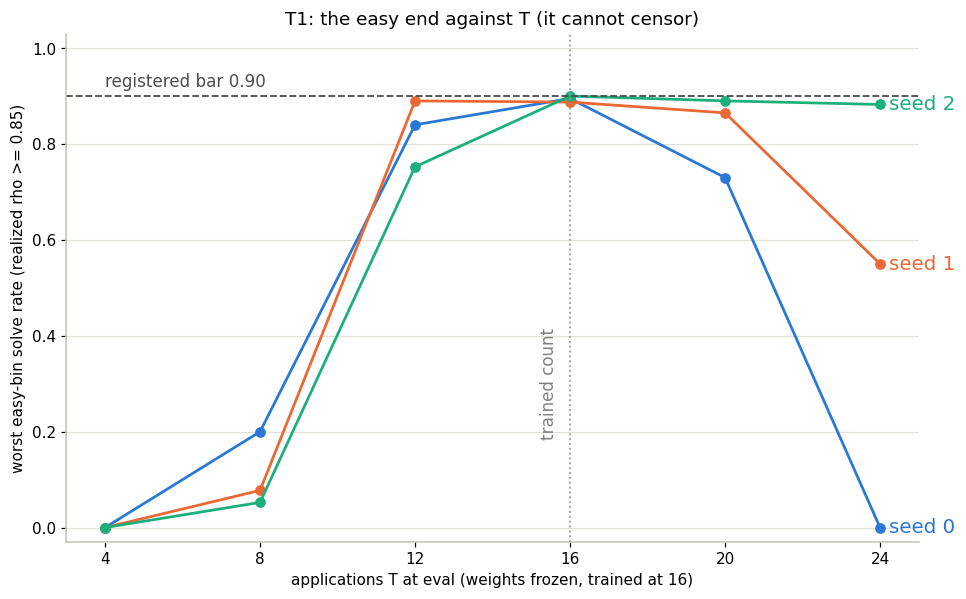

In [5]:
import matplotlib.pyplot as plt
from notebooks.make_staget_deck import (draw_easy, draw_level, draw_mean,
                                        draw_curves, draw_deltas)

fig, ax = plt.subplots(figsize=(10, 6))
draw_easy(ax, easy, seeds, ts)
ax.set_title("T1: the easy end against T (it cannot censor)")
plt.show()

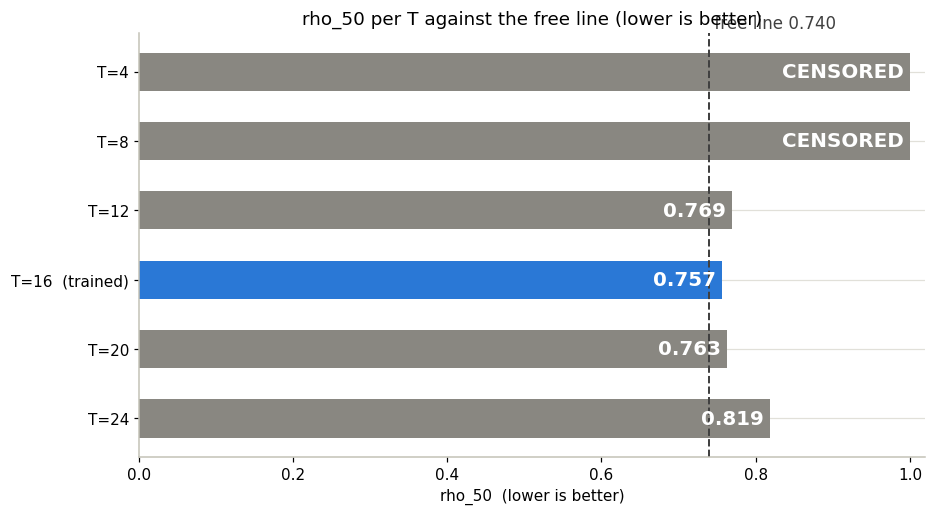

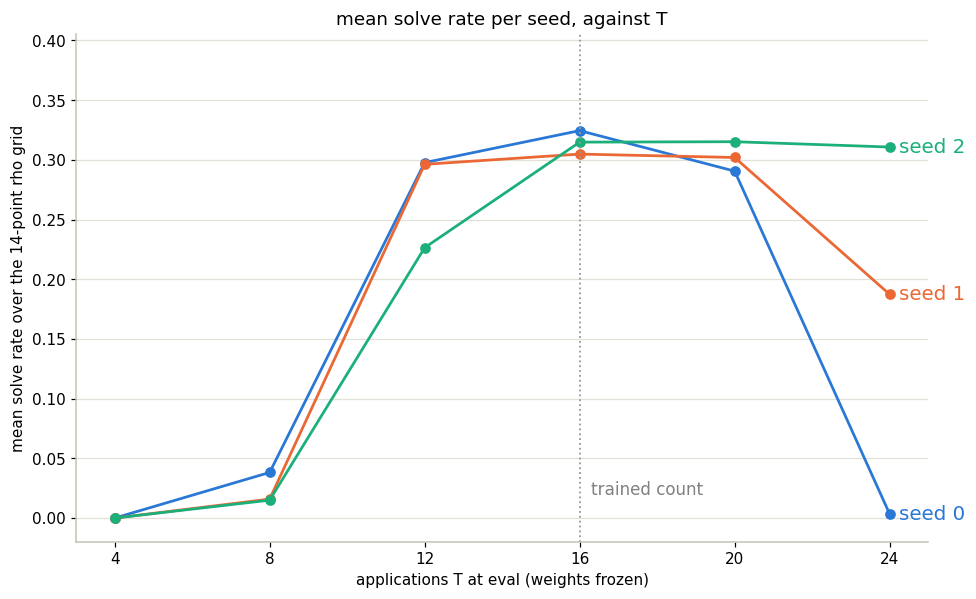

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
draw_level(ax, level, ts)
ax.set_title("rho_50 per T against the free line (lower is better)")
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
draw_mean(ax, level, seeds, ts)
ax.set_title("mean solve rate per seed, against T")
plt.show()

The peak is a statement about the **median over seeds**, and not every
seed peaks at 16: seed 2 is flat out to `T=20`. The margin there is 0.0004,
smaller than anything this eval resolves, but it is the reason the deck's page
says "no seed improves past `T=20`; 2 of 3 peak at 16" rather than the draft's
"all three seeds peak at 16".

In [7]:
from notebooks.make_staget_deck import mean_peaks

peaks_by_seed = mean_peaks(level, seeds, ts)
print("%-6s %18s %12s %12s" % ("seed", "argmax mean_solve", "its value",
                               "at T=16"))
for s in seeds:
    arg, hi, at16 = peaks_by_seed[s]
    print("%-6d %18d %12.4f %12.4f" % (s, arg, hi, at16))
print()
print("seeds peaking at the trained count: %d of %d"
      % (sum(1 for s in seeds if peaks_by_seed[s][0] == TRAINED_T), len(seeds)))
print("median mean_solve peaks at T =", peak)

seed    argmax mean_solve    its value      at T=16
0                      16       0.3245       0.3245
1                      16       0.3048       0.3048
2                      20       0.3152       0.3148

seeds peaking at the trained count: 2 of 3
median mean_solve peaks at T = 16


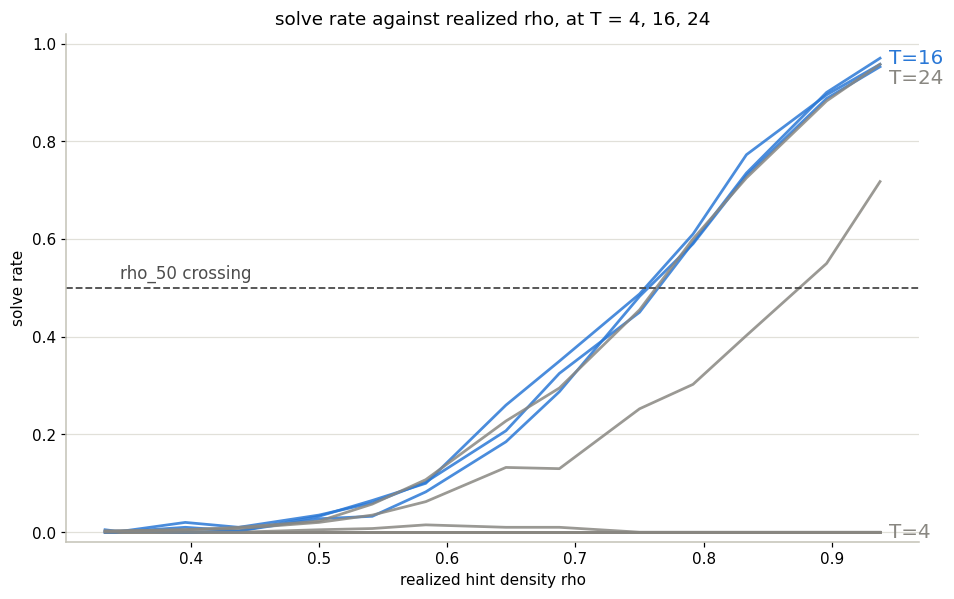

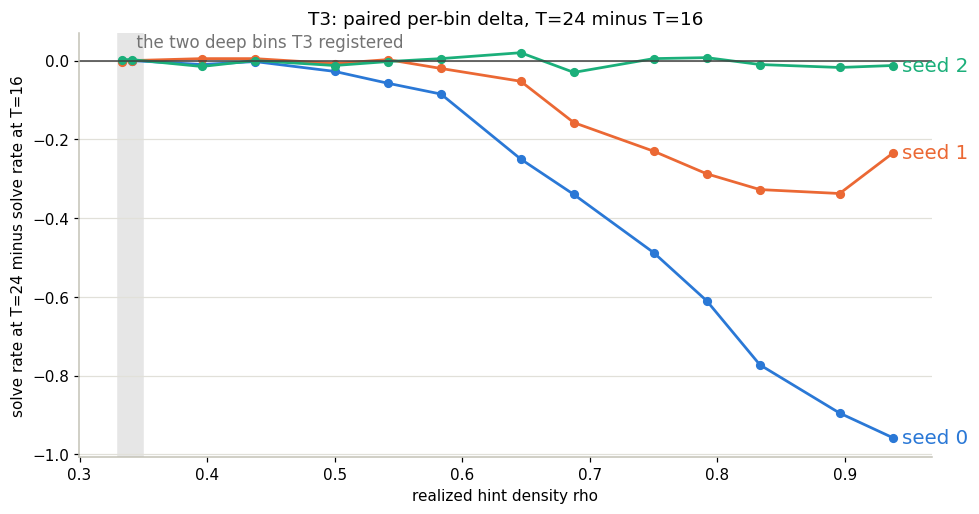

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
draw_curves(ax, groups, seeds)
ax.set_title("solve rate against realized rho, at T = 4, 16, 24")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
draw_deltas(ax, deltas)
ax.set_title("T3: paired per-bin delta, T=24 minus T=16")
plt.show()

## Comparison against the previous best, on the same eval

Same 14-point grid, same 400 instances per bin, same `--shuffle-adj --fall`.
**No improvement is claimed, and none is available here:** stage T trains
nothing, so the best it can do is find a `T` that reads better than the trained
count, and there is none.

In [9]:
print("%-22s %26s %26s" % ("quantity", "J2 untied d192 (standing)",
                                 "S1 tied d320 at best T"))
for q, a, b in [
        ("rho_50 median", "%.3f" % J2_RHO50, lvl_txt(base["rho50"])),
        ("best T over the sweep", "n/a (depth is its weights)", "T=%d" % best),
        ("mean solve", "--", "%.4f" % base["mean_solve"]),
        ("trainable", "{:,}".format(J2_TRAINABLE), "{:,}".format(
            int(rows[0]["n_trainable_params"]))),
        ("distinct blocks", "16", "1"),
        ("seeds crossing 0.5", "3/3", "%d/%d" % (base["crossed"], base["n"]))]:
    print("%-22s %26s %26s" % (q, a, b))

quantity                J2 untied d192 (standing)     S1 tied d320 at best T
rho_50 median                               0.580                      0.757
best T over the sweep  n/a (depth is its weights)                       T=16
mean solve                                     --                     0.3148
trainable                               2,504,890                    613,818
distinct blocks                                16                          1
seeds crossing 0.5                            3/3                        3/3


## What this licenses, and what is already running

T0 falsified means the recurrence is a **schedule**, not an operator, so "one
application = one deduction round" is a reading of a trained network rather than
a property of the architecture. The registered T5 says that in that case the
analyzability route goes back to the shallow untied hub (`full L=6 d256`, six
composed layers, `rho_50` 0.592, already free).

There is one cut in between, and it is the one stage T points at directly: if a
single weight set tuned to sixteen steps is the problem, **`k` distinct blocks
cycled `T/k` times** relieves exactly that while staying one iterated map,
`G = F_{k−1} ∘ … ∘ F_0` applied `16/k` times. That is **stage U**, array
`51922710`, six cells (`k ∈ {2,4}` × three seeds), registered as `b72a74c` by
job `51922709` and running as this notebook is written.

Stage U's accuracy requirement was registered in advance and is already known to
be undecidable on accuracy alone: the gain it needs is 0.0011 of token accuracy
and `k=1`'s own seed spread is 0.0010. The call falls to whether all three seeds
cross 0.5 on the pooled eval.